## Karcher mean vs Arimetric mean: 

In [27]:
import autograd.numpy as np
import pymanopt
from pymanopt.manifolds import sphere
from pymanopt.manifolds import positive_definite
from pymanopt.tools import diagnostics
from scipy.optimize import minimize
import torch

In [50]:
n=5

list_spd = []
N = 50
for i in range(N):
    M = np.random.randn(n, n)
    list_spd.append(M.T @ M + 1e-6 * np.eye(n))

mean_arith = sum(list_spd)/N

manifold = positive_definite.SymmetricPositiveDefinite(n)

In [51]:
def matrix_log(A):
    eigenvalues, U = np.linalg.eigh(A)
    return U @ np.diag(np.log(eigenvalues)) @ U.T
def matrix_power(A, p):
    eigenvalues, U = np.linalg.eigh(A)
    return U @ np.diag(eigenvalues**p) @ U.T
@pymanopt.function.autograd(manifold)
def cost(point):
    cost = 0
    for i in range(N):
        cost += np.linalg.norm( matrix_log(matrix_power(list_spd[i], -1/2) @ point @ matrix_power(list_spd[i], -1/2)))**2 
    return cost/N

def grad(point):
    grad = np.zeros((n,n))
    for i in range(N):
        grad += 2 * matrix_power(list_spd[i], 1/2) @ matrix_log(matrix_power(list_spd[i], -1/2) @ point @ matrix_power(list_spd[i], -1/2)) @ matrix_power(list_spd[i], -1/2) @ point
    return grad / N

problem = pymanopt.Problem(manifold, cost)

Directional derivative check. The slope of the continuous line should match that of the dashed (reference) line over at least a few orders of magnitude for h.


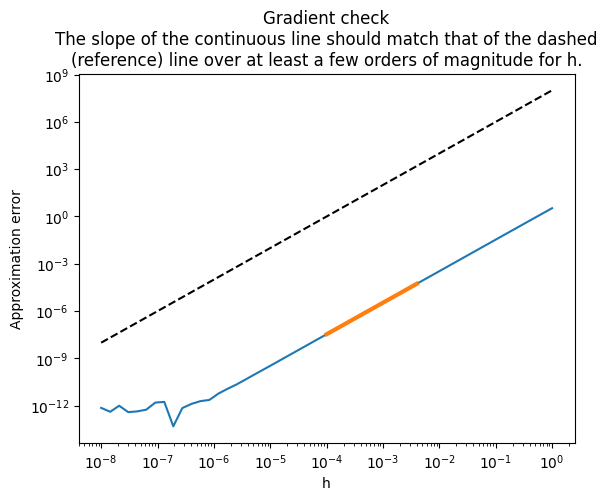

The residual should be close to 0: 0.
If it is far from 0, then the gradient is not in the tangent space.


In [52]:
x = problem.manifold.random_point()
d = grad(x)
diagnostics.check_gradient(problem, x, d)

In [53]:
optimizer= pymanopt.optimizers.SteepestDescent(verbosity=0)
result = optimizer.run(problem)
mean_kar = result.point
print(f"The Frobenius distance between 2 means: {np.linalg.norm(mean_arith - mean_kar)}")

The Frobenius distance between 2 means: 7.759651132669817


## Euclidean methods: 

In [56]:
def l_bfgs(A_0):
    L_0 = np.linalg.cholesky(A_0)
    n = A_0.shape[0]

    tril = np.tril_indices(n)
    is_diag = tril[0] == tril[1]

    def loss_cholesky(theta):
        vec = theta.copy()
        vec[is_diag] = np.exp(theta[is_diag])

        Lmat = np.zeros((n, n))
        Lmat[tril] = vec

        A = Lmat @ Lmat.T

        return cost(A)

    theta0 = L_0[tril].copy()
    theta0[is_diag] = np.log(theta0[is_diag])

    res = minimize(
        loss_cholesky,
        theta0,
        method="L-BFGS-B",
        options={
            "maxiter": 500,
            "gtol": 1e-6
        }
    )

    # Recover the optimized SPD matrix
    vec = res.x.copy()
    vec[is_diag] = np.exp(vec[is_diag])

    L_opt = np.zeros((n, n))
    L_opt[tril] = vec

    A_opt = L_opt @ L_opt.T

    return A_opt, res


In [57]:
for i in range(10):
    A_opt, res = l_bfgs(mean_kar + 10*i * np.eye(n))
    print(f"Run {i}: {np.linalg.norm(A_opt - mean_kar)}")

Run 0: 5.280594092808243e-08
Run 1: 8.202793488065117e-05
Run 2: 0.00014389699134699141
Run 3: 0.00016485534853023738
Run 4: 0.00015732920555580046
Run 5: 0.00013459760177985126
Run 6: 0.00017595016845270743
Run 7: 0.00014448151959579116
Run 8: 0.00016280582772642513
Run 9: 0.0002073391213234759
